# Locate every vehicle in a video

A clip from a car show: a row of cars and a truck, and a car that rises into the air and flies out of the picture. Find every vehicle in every frame, each with its own box, so you can draw them, track them or count them.

1. Take the clip's frames.
2. Ask each frame for an array of boxes.
3. Draw the boxes and put the frames back together.

Paste your TypeLLM API key in the cell below, then run all cells.

In [1]:
%pip install -q "typellm>=0.7.2" pillow


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: /private/tmp/claude-501/-Users-mingtian-work-DNova/beddee30-2a48-449c-8e70-9a956c432690/scratchpad/nb/venv/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
# Paste your API key here.
TYPELLM_API_KEY = ""  # https://typellm.ai/dashboard/keys

In [3]:
import glob
import json
import os
import urllib.request
import zipfile

from PIL import Image
from typellm import TypeLLMClient

client = TypeLLMClient(api_key=TYPELLM_API_KEY, timeout=90)

FRAMES = "data/car_show_frames.zip"  # seconds 12 to 16 of the show, 8 frames a second
if not os.path.exists(FRAMES):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/TypeLLM/TypeLLM/main/examples/notebooks/data/car_show_frames.zip", FRAMES)

## Take the frames

TypeLLM reads images, so a video goes in as its frames. These are seconds 12 to 16 of the show, eight a second, at 1920 by 1080, taken with [ffmpeg](https://ffmpeg.org):

```bash
ffmpeg -ss 12 -t 4 -i show.mp4 -vf scale=1920:-2 -r 8 frames/f%03d.jpg
```

Run that on your own video to take its frames.

34 frames of (1920, 1080)


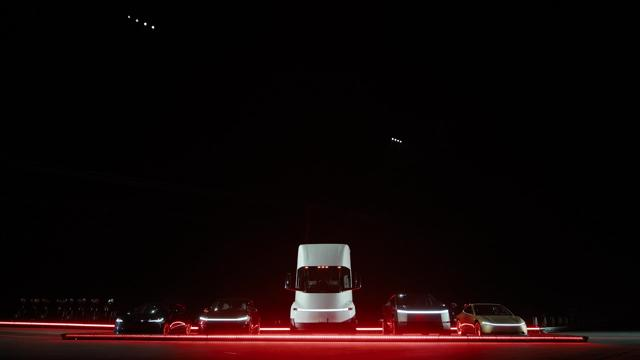

In [4]:
START, FPS = 12, 8  # where the clip starts in the show, and frames a second

with zipfile.ZipFile(FRAMES) as archive:
    archive.extractall("frames")
frames = sorted(glob.glob("frames/*.jpg"))
print(f"{len(frames)} frames of {Image.open(frames[0]).size}")
Image.open(frames[0]).resize((640, 360))

## Ask each frame for its vehicles

An [array of boxes](https://typellm.ai/docs/output-types#arrays-of-boxes) finds every match in an image, each as its `top`, `bottom`, `left` and `right` edges, from 0 to 1. Say in its instructions what counts: here the truck does, and so does a car in the air.

In [5]:
QUESTIONS = {
    "vehicles": {
        "type": "array",
        "items": {"type": "box"},
        "instructions": ("Every vehicle, each on its own: every car, the truck, "
                         "and any vehicle in the air."),
    },
}

Each frame is one call, and the calls run side by side.

In [6]:
from concurrent.futures import ThreadPoolExecutor


def locate(frame):
    response = client.generate(
        context="A frame of a video of a car show.",
        images=[frame],
        questions=QUESTIONS,
    )
    return response.result["vehicles"], response.usage.input_tokens


with ThreadPoolExecutor(4) as pool:
    answers = list(pool.map(locate, frames))
vehicles = [boxes for boxes, _ in answers]

for i, boxes in enumerate(vehicles):
    print(f"{START + i / FPS:6.2f} s  {len(boxes)} vehicles")
print(f"{sum(tokens for _, tokens in answers)} input tokens in all")

 12.00 s  5 vehicles
 12.12 s  5 vehicles
 12.25 s  5 vehicles
 12.38 s  5 vehicles
 12.50 s  5 vehicles
 12.62 s  5 vehicles
 12.75 s  5 vehicles
 12.88 s  5 vehicles
 13.00 s  5 vehicles
 13.12 s  5 vehicles
 13.25 s  5 vehicles
 13.38 s  6 vehicles
 13.50 s  6 vehicles
 13.62 s  6 vehicles
 13.75 s  6 vehicles
 13.88 s  6 vehicles
 14.00 s  6 vehicles
 14.12 s  6 vehicles
 14.25 s  6 vehicles
 14.38 s  6 vehicles
 14.50 s  6 vehicles
 14.62 s  6 vehicles
 14.75 s  6 vehicles
 14.88 s  6 vehicles
 15.00 s  6 vehicles
 15.12 s  6 vehicles
 15.25 s  6 vehicles
 15.38 s  5 vehicles
 15.50 s  5 vehicles
 15.62 s  5 vehicles
 15.75 s  5 vehicles
 15.88 s  5 vehicles
 16.00 s  5 vehicles
 16.12 s  5 vehicles
71264 input tokens in all


Each frame's answer is its list of boxes. Here is one with the car in the air, the last box:

In [7]:
print(json.dumps(vehicles[14], indent=1))

[
 {
  "top": 0.839,
  "bottom": 0.931,
  "left": 0.177,
  "right": 0.3
 },
 {
  "top": 0.827,
  "bottom": 0.925,
  "left": 0.309,
  "right": 0.405
 },
 {
  "top": 0.675,
  "bottom": 0.923,
  "left": 0.444,
  "right": 0.565
 },
 {
  "top": 0.811,
  "bottom": 0.931,
  "left": 0.597,
  "right": 0.705
 },
 {
  "top": 0.841,
  "bottom": 0.937,
  "left": 0.712,
  "right": 0.825
 },
 {
  "top": 0.493,
  "bottom": 0.597,
  "left": 0.699,
  "right": 0.871
 }
]


## Draw the boxes

The edges are fractions, so they fit the frame at any size: multiply by its width and height.

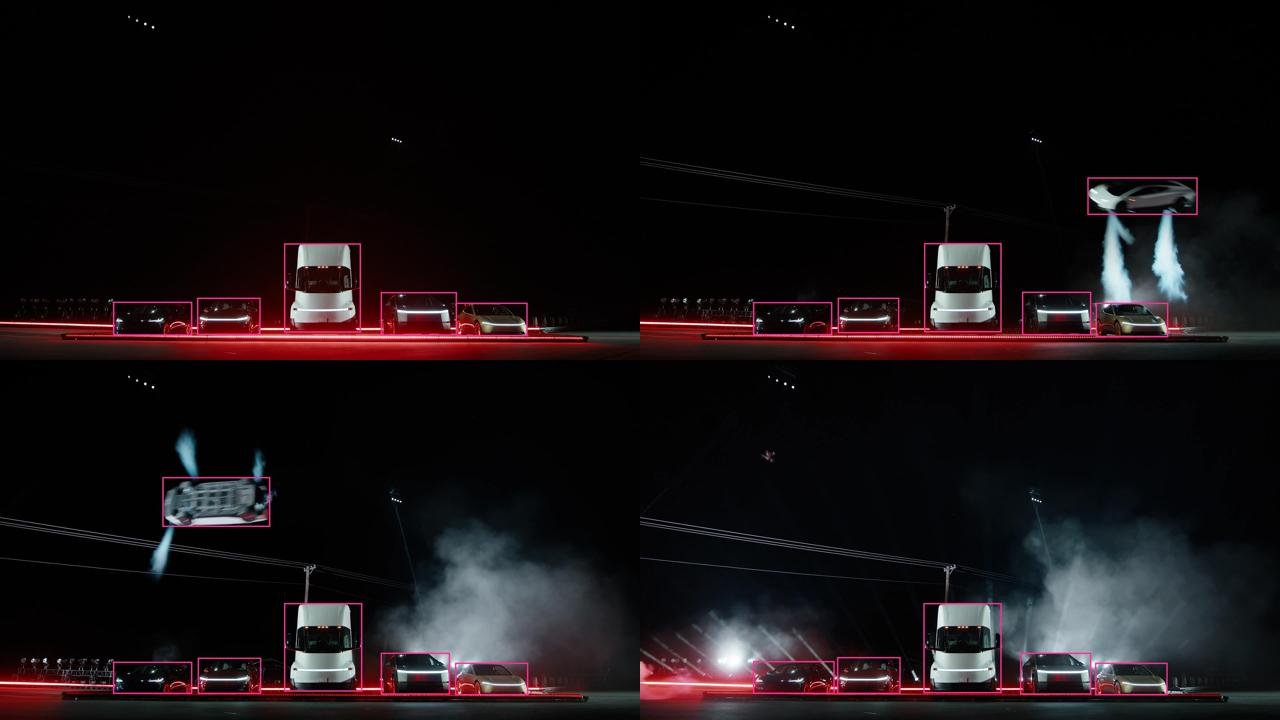

In [8]:
from PIL import ImageDraw

os.makedirs("boxed", exist_ok=True)
for frame, boxes in zip(frames, vehicles):
    image = Image.open(frame).convert("RGB")
    width, height = image.size
    draw = ImageDraw.Draw(image)
    for box in boxes:
        edges = (box["left"] * width, box["top"] * height,
                 box["right"] * width, box["bottom"] * height)
        draw.rectangle(edges, outline=(255, 45, 149), width=4)
    image.save(os.path.join("boxed", os.path.basename(frame)))

# Four frames: before the car rises, in the air, turning over, and after it has flown out.
picks = [0, 14, 22, len(frames) - 1]
sheet = Image.new("RGB", (1280, 720))
for k, i in enumerate(picks):
    sheet.paste(Image.open(f"boxed/{os.path.basename(frames[i])}").resize((640, 360)), ((k % 2) * 640, (k // 2) * 360))
sheet

Put the boxed frames back together as an animated GIF, eight frames a second:

In [9]:
boxed = [Image.open(f"boxed/{os.path.basename(frame)}").resize((960, 540)) for frame in frames]
boxed[0].save("boxed.gif", save_all=True, append_images=boxed[1:], duration=1000 // FPS, loop=0)
print(f"boxed.gif: {len(boxed)} frames")

boxed.gif: 34 frames


A frame without a vehicle comes back as `[]`, not with a box around the nearest thing. Each frame is read on its own, so a vehicle that is hard to see in one frame can be missed there and found in the next; if you track vehicles across frames, let a vehicle missed in a single frame carry over from its neighbours.